In [1]:
# ==========================================================
# MACHINE LEARNING - AIR QUALITY ROBUSTNESS ANALYSIS
# ==========================================================

# STEP 1: IMPORT LIBRARIES

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
    accuracy_score,
    classification_report,
    confusion_matrix
)

from sklearn.cluster import KMeans

import warnings
warnings.filterwarnings("ignore")

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [2]:
# ==========================================================
#  LOAD DATASET
# ==========================================================

file_path = r"C:\Users\baris\OneDrive\Desktop\Air_Quality_Research\dataset\INDIA_AQI_COMPLETE_20251126.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

Dataset loaded successfully!
Shape of dataset: (842160, 71)


In [3]:
# ==========================================================
#  TARGET VARIABLE CHECK
# ==========================================================

print("Target Variable: US_AQI")
print("\nUS_AQI Data Type:", df["US_AQI"].dtype)
print("Missing US_AQI Values:", df["US_AQI"].isnull().sum())

print("\nUS_AQI Statistics:")
print(df["US_AQI"].describe())

Target Variable: US_AQI

US_AQI Data Type: float64
Missing US_AQI Values: 145

US_AQI Statistics:
count    842015.000000
mean         96.804419
std          70.784455
min           9.000000
25%          59.000000
50%          84.000000
75%         128.000000
max        2742.000000
Name: US_AQI, dtype: float64


In [4]:
# ==========================================================
#  FEATURE SELECTION & DATA LEAKAGE PREVENTION
# ==========================================================

# Target variable
target = "US_AQI"

# Columns that may cause data leakage
leakage_columns = [
    "US_AQI",
    "US_AQI_PM25",
    "US_AQI_PM10",
    "US_AQI_NO2",
    "US_AQI_O3",
    "US_AQI_CO",
    "EU_AQI",
    "EU_AQI_PM25",
    "EU_AQI_PM10",
    "AQI_Category",
    "PM25_Category_India"
]

# Columns with 100% missing values
fully_missing_columns = [
    "Temp_80m_C",
    "Temp_120m_C",
    "Temp_180m_C",
    "Wind_Speed_80m_kmh",
    "Wind_Speed_120m_kmh",
    "UV_Index",
    "NH3_ugm3",
    "Inversion_Strength_C"
]

# Raw datetime column
datetime_columns = ["Datetime"]

# Combine columns to remove
columns_to_remove = (
    leakage_columns
    + fully_missing_columns
    + datetime_columns
)

# Remove duplicate column names
columns_to_remove = list(dict.fromkeys(columns_to_remove))

# Create feature dataframe
X = df.drop(columns=columns_to_remove)

# Create target dataframe
y = df[target]

print("Feature selection completed successfully!")

print("\nOriginal Dataset Shape:", df.shape)
print("Feature Dataset Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nRemoved Columns:")
for column in columns_to_remove:
    print("-", column)

print("\nRemaining Features:")
print(X.columns.tolist())

Feature selection completed successfully!

Original Dataset Shape: (842160, 71)
Feature Dataset Shape: (842160, 51)
Target Shape: (842160,)

Removed Columns:
- US_AQI
- US_AQI_PM25
- US_AQI_PM10
- US_AQI_NO2
- US_AQI_O3
- US_AQI_CO
- EU_AQI
- EU_AQI_PM25
- EU_AQI_PM10
- AQI_Category
- PM25_Category_India
- Temp_80m_C
- Temp_120m_C
- Temp_180m_C
- Wind_Speed_80m_kmh
- Wind_Speed_120m_kmh
- UV_Index
- NH3_ugm3
- Inversion_Strength_C
- Datetime

Remaining Features:
['City', 'State', 'Latitude', 'Longitude', 'Year', 'Month', 'Day', 'Hour', 'Day_of_Week', 'Day_Name', 'Week_of_Year', 'Is_Weekend', 'Quarter', 'Season', 'Time_of_Day', 'Temp_2m_C', 'Humidity_Percent', 'Dew_Point_C', 'Humidity_Category', 'Wind_Speed_10m_kmh', 'Wind_Dir_10m', 'Wind_Gusts_kmh', 'Wind_Category', 'Wind_Stagnation', 'Precipitation_mm', 'Rain_mm', 'Is_Raining', 'Heavy_Rain', 'Pressure_MSL_hPa', 'Surface_Pressure_hPa', 'Solar_Radiation_Wm2', 'Direct_Radiation_Wm2', 'Diffuse_Radiation_Wm2', 'Cloud_Cover_Percent', 'Cloud

In [5]:
# ==========================================================
#  MISSING VALUE CHECK
# ==========================================================

print("Missing Values in Features:")
print(X.isnull().sum()[X.isnull().sum() > 0])

print("\nTotal Missing Values in Features:", X.isnull().sum().sum())

print("\nMissing Values in Target (US_AQI):", y.isnull().sum())

print("\nTotal Rows Before Cleaning:", len(X))

Missing Values in Features:
Series([], dtype: int64)

Total Missing Values in Features: 0

Missing Values in Target (US_AQI): 145

Total Rows Before Cleaning: 842160


In [6]:
# ==========================================================
#  REMOVE ROWS WITH MISSING TARGET
# ==========================================================

# Keep only rows where US_AQI is available
valid_rows = y.notnull()

X_clean = X.loc[valid_rows].copy()
y_clean = y.loc[valid_rows].copy()

print("Missing target rows removed successfully!")

print("\nOriginal Rows:", len(X))
print("Removed Rows:", len(X) - len(X_clean))
print("Remaining Rows:", len(X_clean))

print("\nMissing Values in X_clean:", X_clean.isnull().sum().sum())
print("Missing Values in y_clean:", y_clean.isnull().sum())

Missing target rows removed successfully!

Original Rows: 842160
Removed Rows: 145
Remaining Rows: 842015

Missing Values in X_clean: 0
Missing Values in y_clean: 0


In [7]:
# ==========================================================
#  CATEGORICAL FEATURE ENCODING
# ==========================================================

# Identify categorical columns
categorical_columns = X_clean.select_dtypes(
    include=["object"]
).columns.tolist()

print("Categorical Columns:")
print(categorical_columns)

print("\nNumber of Categorical Columns:", len(categorical_columns))

# One-Hot Encoding
X_encoded = pd.get_dummies(
    X_clean,
    columns=categorical_columns,
    drop_first=True
)

print("\nEncoding completed successfully!")

print("Original Feature Count:", X_clean.shape[1])
print("Encoded Feature Count:", X_encoded.shape[1])

print("\nEncoded Dataset Shape:", X_encoded.shape)

print("\nData Types:")
print(X_encoded.dtypes.value_counts())

Categorical Columns:
['City', 'State', 'Day_Name', 'Season', 'Time_of_Day', 'Humidity_Category', 'Wind_Category']

Number of Categorical Columns: 7

Encoding completed successfully!
Original Feature Count: 51
Encoded Feature Count: 122

Encoded Dataset Shape: (842015, 122)

Data Types:
bool       78
float64    23
int64      21
Name: count, dtype: int64


In [8]:
# ==========================================================
#  FINAL NUMERIC CONVERSION & DATA CHECK
# ==========================================================

# Convert boolean columns to integer (0 and 1)
X_encoded = X_encoded.astype(float)

print("All features converted to numeric format!")

print("\nDataset Shape:", X_encoded.shape)

print("\nData Types After Conversion:")
print(X_encoded.dtypes.value_counts())

print("\nTotal Missing Values:", X_encoded.isnull().sum().sum())

print("\nInfinite Values:")
print(np.isinf(X_encoded).sum().sum())

print("\nTarget Data Type:", y_clean.dtype)

print("\nTarget Missing Values:", y_clean.isnull().sum())

All features converted to numeric format!

Dataset Shape: (842015, 122)

Data Types After Conversion:
float64    122
Name: count, dtype: int64

Total Missing Values: 0

Infinite Values:
0

Target Data Type: float64

Target Missing Values: 0


In [9]:
# ==========================================================
#  CHRONOLOGICAL TRAIN-TEST SPLIT
# ==========================================================

# Get Datetime for the rows used in the cleaned dataset
datetime_clean = pd.to_datetime(
    df.loc[y_clean.index, "Datetime"]
)

# Sort indices chronologically
sorted_indices = datetime_clean.sort_values().index

# Reorder features and target chronologically
X_sorted = X_encoded.loc[sorted_indices].copy()
y_sorted = y_clean.loc[sorted_indices].copy()

# 80% training, 20% testing
split_point = int(len(X_sorted) * 0.80)

X_train = X_sorted.iloc[:split_point].copy()
X_test = X_sorted.iloc[split_point:].copy()

y_train = y_sorted.iloc[:split_point].copy()
y_test = y_sorted.iloc[split_point:].copy()

print("Chronological train-test split completed!")

print("\nTraining Data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting Data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTraining Period:")
print(datetime_clean.loc[X_train.index].min())
print("to")
print(datetime_clean.loc[X_train.index].max())

print("\nTesting Period:")
print(datetime_clean.loc[X_test.index].min())
print("to")
print(datetime_clean.loc[X_test.index].max())

Chronological train-test split completed!

Training Data:
X_train: (673612, 122)
y_train: (673612,)

Testing Data:
X_test: (168403, 122)
y_test: (168403,)

Training Period:
2022-08-05 05:00:00
to
2025-03-30 00:00:00

Testing Period:
2025-03-30 01:00:00
to
2025-11-26 23:00:00


In [10]:
# ==========================================================
#  FEATURE SCALING
# ==========================================================

# Create StandardScaler
scaler = StandardScaler()

# Fit scaler only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

print("\nTraining Data Shape:", X_train_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)

print("\nTraining Mean (approximately):", X_train_scaled.mean())
print("Training Standard Deviation (approximately):", X_train_scaled.std())

print("\nTest Data Shape:", X_test_scaled.shape)

Feature scaling completed successfully!

Training Data Shape: (673612, 122)
Testing Data Shape: (168403, 122)

Training Mean (approximately): -1.0185540740680094e-15
Training Standard Deviation (approximately): 0.9958932064677037

Test Data Shape: (168403, 122)


#  LINEAR REGRESSION

In [11]:
# ==========================================================
#  LINEAR REGRESSION
# ==========================================================

# Create Linear Regression model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train_scaled, y_train)

# Predict US_AQI on test data
y_pred_linear = linear_model.predict(X_test_scaled)

print("Linear Regression training completed!")
print("Predictions generated successfully!")

print("\nNumber of Predictions:", len(y_pred_linear))

Linear Regression training completed!
Predictions generated successfully!

Number of Predictions: 168403


In [12]:
# ==========================================================
#  LINEAR REGRESSION EVALUATION
# ==========================================================

# Calculate evaluation metrics
linear_mae = mean_absolute_error(y_test, y_pred_linear)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_linear)
)

linear_r2 = r2_score(y_test, y_pred_linear)

# Display results
print("Linear Regression Performance")
print("=" * 40)

print(f"MAE  : {linear_mae:.4f}")
print(f"RMSE : {linear_rmse:.4f}")
print(f"R²   : {linear_r2:.4f}")

Linear Regression Performance
MAE  : 23.3420
RMSE : 56.5912
R²   : 0.7460


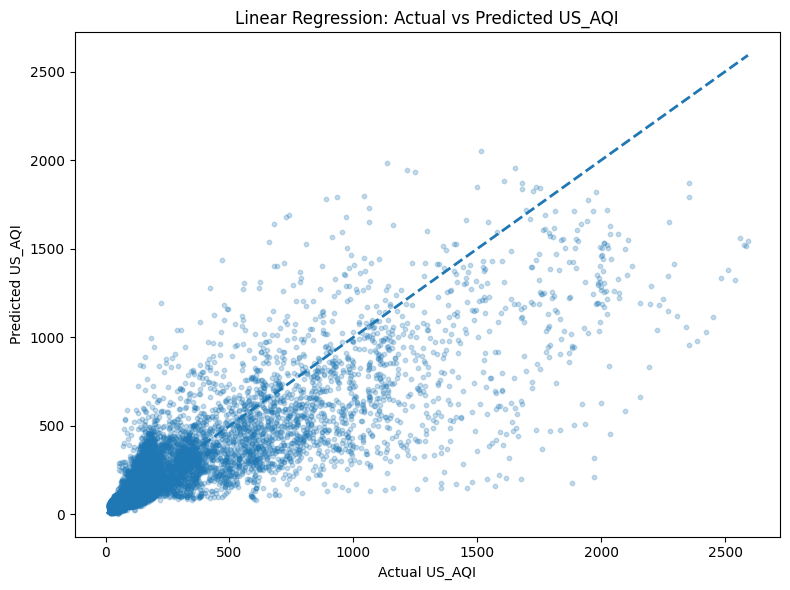

In [13]:
# ==========================================================
#  ACTUAL vs PREDICTED - LINEAR REGRESSION
# ==========================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_linear,
    alpha=0.25,
    s=10
)

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred_linear.min())
max_value = max(y_test.max(), y_pred_linear.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    linewidth=2
)

plt.xlabel("Actual US_AQI")
plt.ylabel("Predicted US_AQI")
plt.title("Linear Regression: Actual vs Predicted US_AQI")

plt.tight_layout()
plt.show()

In [14]:
# ==========================================================
#  EXTREME POLLUTION CHECK
# ==========================================================

# Define extreme pollution threshold
EXTREME_AQI = 201

# Identify extreme observations in test set
extreme_mask = y_test >= EXTREME_AQI

# Create extreme subset
y_test_extreme = y_test[extreme_mask]
y_pred_linear_extreme = y_pred_linear[extreme_mask]

print("Extreme Pollution Threshold:", EXTREME_AQI)

print("\nTotal Test Observations:", len(y_test))
print("Extreme Test Observations:", len(y_test_extreme))

print(
    "Extreme Test Percentage:",
    f"{(len(y_test_extreme) / len(y_test)) * 100:.2f}%"
)

print("\nExtreme AQI Range:")
print("Minimum:", y_test_extreme.min())
print("Maximum:", y_test_extreme.max())

Extreme Pollution Threshold: 201

Total Test Observations: 168403
Extreme Test Observations: 4321
Extreme Test Percentage: 2.57%

Extreme AQI Range:
Minimum: 201.0
Maximum: 2592.0


In [15]:
# ==========================================================
#  LINEAR REGRESSION - EXTREME POLLUTION PERFORMANCE
# ==========================================================

# Calculate metrics for extreme pollution observations
linear_extreme_mae = mean_absolute_error(
    y_test_extreme,
    y_pred_linear_extreme
)

linear_extreme_rmse = np.sqrt(
    mean_squared_error(
        y_test_extreme,
        y_pred_linear_extreme
    )
)

linear_extreme_r2 = r2_score(
    y_test_extreme,
    y_pred_linear_extreme
)

# Display results
print("Linear Regression - Extreme Pollution Performance")
print("=" * 55)

print(f"Extreme MAE  : {linear_extreme_mae:.4f}")
print(f"Extreme RMSE : {linear_extreme_rmse:.4f}")
print(f"Extreme R²   : {linear_extreme_r2:.4f}")

Linear Regression - Extreme Pollution Performance
Extreme MAE  : 201.9742
Extreme RMSE : 313.5034
Extreme R²   : 0.4916


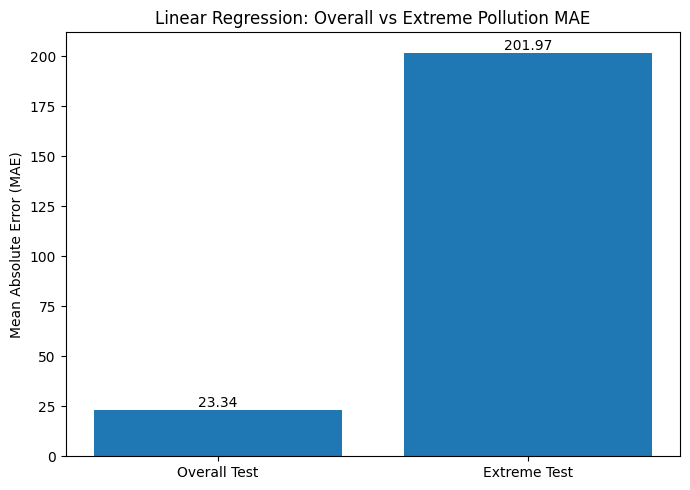

In [16]:
# ==========================================================
#  LINEAR REGRESSION - MAE COMPARISON
# ==========================================================

comparison_labels = ["Overall Test", "Extreme Test"]
comparison_mae = [linear_mae, linear_extreme_mae]

plt.figure(figsize=(7, 5))

bars = plt.bar(
    comparison_labels,
    comparison_mae
)

plt.ylabel("Mean Absolute Error (MAE)")
plt.title("Linear Regression: Overall vs Extreme Pollution MAE")

# Add values on top of bars
for bar, value in zip(bars, comparison_mae):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [17]:
# ==========================================================
#  EXTREME POLLUTION CLASSIFICATION TARGET
# ==========================================================

# Classification threshold
EXTREME_AQI = 201

# Create binary target
y_train_class = (y_train >= EXTREME_AQI).astype(int)
y_test_class = (y_test >= EXTREME_AQI).astype(int)

print("Classification target created successfully!")

print("\nTraining Class Distribution:")
print(y_train_class.value_counts().sort_index())

print("\nTraining Class Percentage:")
print(
    (y_train_class.value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

print("\nTesting Class Distribution:")
print(y_test_class.value_counts().sort_index())

print("\nTesting Class Percentage:")
print(
    (y_test_class.value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

Classification target created successfully!

Training Class Distribution:
US_AQI
0    663569
1     10043
Name: count, dtype: int64

Training Class Percentage:
US_AQI
0    98.51
1     1.49
Name: proportion, dtype: float64

Testing Class Distribution:
US_AQI
0    164082
1      4321
Name: count, dtype: int64

Testing Class Percentage:
US_AQI
0    97.43
1     2.57
Name: proportion, dtype: float64


#  LOGISTIC REGRESSION

In [18]:
# ==========================================================
#  LOGISTIC REGRESSION
# ==========================================================

# Create Logistic Regression model
logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Train the model
logistic_model.fit(
    X_train_scaled,
    y_train_class
)

# Predict classes on test data
y_pred_logistic = logistic_model.predict(X_test_scaled)

print("Logistic Regression training completed!")
print("Predictions generated successfully!")

print("\nNumber of Predictions:", len(y_pred_logistic))

Logistic Regression training completed!
Predictions generated successfully!

Number of Predictions: 168403


Logistic Regression Performance
Accuracy : 0.9635

Classification Report:
              precision    recall  f1-score   support

 Non-Extreme     0.9986    0.9639    0.9810    164082
     Extreme     0.4091    0.9482    0.5716      4321

    accuracy                         0.9635    168403
   macro avg     0.7039    0.9560    0.7763    168403
weighted avg     0.9835    0.9635    0.9705    168403

Confusion Matrix:
[[158165   5917]
 [   224   4097]]


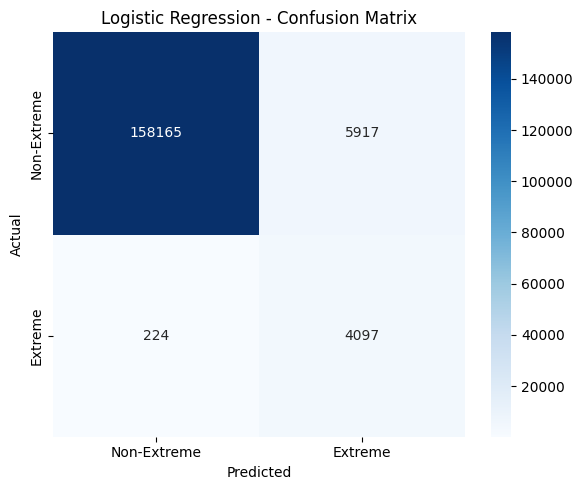

In [19]:
# ==========================================================
#  LOGISTIC REGRESSION EVALUATION
# ==========================================================

# Calculate basic metrics
logistic_accuracy = accuracy_score(
    y_test_class,
    y_pred_logistic
)

logistic_report = classification_report(
    y_test_class,
    y_pred_logistic,
    target_names=["Non-Extreme", "Extreme"],
    digits=4
)

# Display results
print("Logistic Regression Performance")
print("=" * 50)

print(f"Accuracy : {logistic_accuracy:.4f}")

print("\nClassification Report:")
print(logistic_report)

# Confusion Matrix
logistic_cm = confusion_matrix(
    y_test_class,
    y_pred_logistic
)

print("Confusion Matrix:")
print(logistic_cm)

# Plot Confusion Matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    logistic_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Extreme", "Extreme"],
    yticklabels=["Non-Extreme", "Extreme"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")

plt.tight_layout()
plt.show()

In [20]:
# ==========================================================
#  SAVE LOGISTIC REGRESSION RESULTS
# ==========================================================

logistic_extreme_precision = (
    logistic_report.split("Extreme")[1]
)

print("Logistic Regression results recorded successfully!")
print("Accuracy :", f"{logistic_accuracy:.4f}")
print("Confusion Matrix:")
print(logistic_cm)

Logistic Regression results recorded successfully!
Accuracy : 0.9635
Confusion Matrix:
[[158165   5917]
 [   224   4097]]


#  NAIVE BAYES

In [21]:
# ==========================================================
#  NAIVE BAYES
# ==========================================================

from sklearn.utils.class_weight import compute_sample_weight

# Create balanced sample weights
nb_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_class
)

# Create Gaussian Naive Bayes model
naive_bayes_model = GaussianNB()

# Train the model
naive_bayes_model.fit(
    X_train_scaled,
    y_train_class,
    sample_weight=nb_sample_weights
)

# Predict classes on test data
y_pred_nb = naive_bayes_model.predict(X_test_scaled)

print("Naive Bayes training completed!")
print("Predictions generated successfully!")

print("\nNumber of Predictions:", len(y_pred_nb))

Naive Bayes training completed!
Predictions generated successfully!

Number of Predictions: 168403


Naive Bayes Performance
Accuracy : 0.7534

Classification Report:
              precision    recall  f1-score   support

 Non-Extreme     0.9997    0.7471    0.8551    164082
     Extreme     0.0935    0.9910    0.1710      4321

    accuracy                         0.7534    168403
   macro avg     0.5466    0.8690    0.5130    168403
weighted avg     0.9764    0.7534    0.8376    168403

Confusion Matrix:
[[122589  41493]
 [    39   4282]]


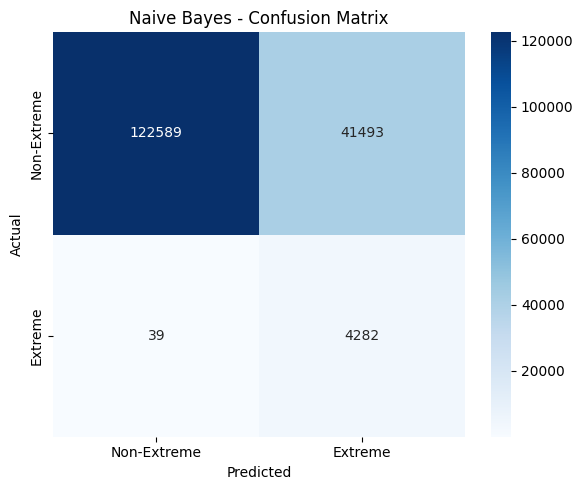

In [22]:
# ==========================================================
#  NAIVE BAYES EVALUATION
# ==========================================================

# Calculate accuracy
nb_accuracy = accuracy_score(
    y_test_class,
    y_pred_nb
)

# Classification report
nb_report = classification_report(
    y_test_class,
    y_pred_nb,
    target_names=["Non-Extreme", "Extreme"],
    digits=4
)

# Confusion matrix
nb_cm = confusion_matrix(
    y_test_class,
    y_pred_nb
)

# Display results
print("Naive Bayes Performance")
print("=" * 50)

print(f"Accuracy : {nb_accuracy:.4f}")

print("\nClassification Report:")
print(nb_report)

print("Confusion Matrix:")
print(nb_cm)

# Plot confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    nb_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Extreme", "Extreme"],
    yticklabels=["Non-Extreme", "Extreme"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Naive Bayes - Confusion Matrix")

plt.tight_layout()
plt.show()

#  SVM 

In [23]:
# ==========================================================
#  LINEAR SVM IMPORT
# ==========================================================

from sklearn.svm import LinearSVC

print("Linear SVM imported successfully!")

Linear SVM imported successfully!


In [24]:
# ==========================================================
#  LINEAR SVM TRAINING
# ==========================================================

# Create Linear SVM model
svm_model = LinearSVC(
    class_weight="balanced",
    max_iter=5000,
    random_state=42
)

# Train the model
svm_model.fit(
    X_train_scaled,
    y_train_class
)

# Predict classes on test data
y_pred_svm = svm_model.predict(X_test_scaled)

print("Linear SVM training completed!")
print("Predictions generated successfully!")

print("\nNumber of Predictions:", len(y_pred_svm))

Linear SVM training completed!
Predictions generated successfully!

Number of Predictions: 168403


Linear SVM Performance
Accuracy : 0.9616

Classification Report:
              precision    recall  f1-score   support

 Non-Extreme     0.9986    0.9619    0.9799    164082
     Extreme     0.3963    0.9502    0.5593      4321

    accuracy                         0.9616    168403
   macro avg     0.6975    0.9561    0.7696    168403
weighted avg     0.9832    0.9616    0.9691    168403

Confusion Matrix:
[[157827   6255]
 [   215   4106]]


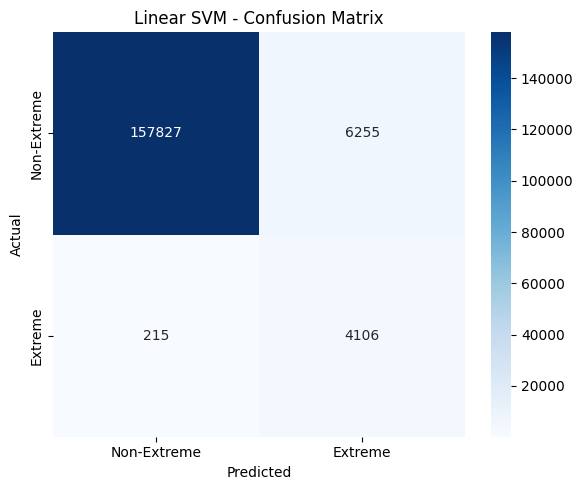

In [25]:
# ==========================================================
#  LINEAR SVM EVALUATION
# ==========================================================

# Calculate accuracy
svm_accuracy = accuracy_score(
    y_test_class,
    y_pred_svm
)

# Classification report
svm_report = classification_report(
    y_test_class,
    y_pred_svm,
    target_names=["Non-Extreme", "Extreme"],
    digits=4
)

# Confusion matrix
svm_cm = confusion_matrix(
    y_test_class,
    y_pred_svm
)

# Display results
print("Linear SVM Performance")
print("=" * 50)

print(f"Accuracy : {svm_accuracy:.4f}")

print("\nClassification Report:")
print(svm_report)

print("Confusion Matrix:")
print(svm_cm)

# Plot confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    svm_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Extreme", "Extreme"],
    yticklabels=["Non-Extreme", "Extreme"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Linear SVM - Confusion Matrix")

plt.tight_layout()
plt.show()

#  RANDOM FOREST CLASSIFIER

In [26]:
# ==========================================================
#  RANDOM FOREST CLASSIFIER
# ==========================================================

# Create Random Forest model
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

# Train the model
random_forest_model.fit(
    X_train,
    y_train_class
)

# Predict classes on test data
y_pred_rf = random_forest_model.predict(X_test)

print("Random Forest training completed!")
print("Predictions generated successfully!")

print("\nNumber of Predictions:", len(y_pred_rf))

Random Forest training completed!
Predictions generated successfully!

Number of Predictions: 168403


Random Forest Performance
Accuracy : 0.9808

Classification Report:
              precision    recall  f1-score   support

 Non-Extreme     0.9807    0.9999    0.9902    164082
     Extreme     0.9892    0.2543    0.4046      4321

    accuracy                         0.9808    168403
   macro avg     0.9850    0.6271    0.6974    168403
weighted avg     0.9810    0.9808    0.9752    168403

Confusion Matrix:
[[164070     12]
 [  3222   1099]]


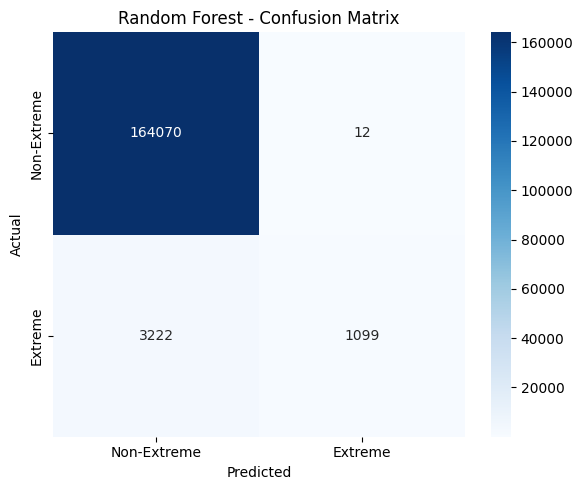

In [27]:
# ==========================================================
#  RANDOM FOREST EVALUATION
# ==========================================================

# Calculate accuracy
rf_accuracy = accuracy_score(
    y_test_class,
    y_pred_rf
)

# Classification report
rf_report = classification_report(
    y_test_class,
    y_pred_rf,
    target_names=["Non-Extreme", "Extreme"],
    digits=4
)

# Confusion matrix
rf_cm = confusion_matrix(
    y_test_class,
    y_pred_rf
)

# Display results
print("Random Forest Performance")
print("=" * 50)

print(f"Accuracy : {rf_accuracy:.4f}")

print("\nClassification Report:")
print(rf_report)

print("Confusion Matrix:")
print(rf_cm)

# Plot confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Extreme", "Extreme"],
    yticklabels=["Non-Extreme", "Extreme"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Confusion Matrix")

plt.tight_layout()
plt.show()

#  XGBOOST 

In [28]:
# ==========================================================
#  XGBOOST IMPORT
# ==========================================================

from xgboost import XGBClassifier

print("XGBoost imported successfully!")

XGBoost imported successfully!


In [29]:
# ==========================================================
#  XGBOOST CLASSIFIER
# ==========================================================

# Calculate class imbalance ratio
negative_count = (y_train_class == 0).sum()
positive_count = (y_train_class == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Scale Pos Weight:", round(scale_pos_weight, 4))

# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train the model
xgb_model.fit(
    X_train,
    y_train_class
)

# Predict classes on test data
y_pred_xgb = xgb_model.predict(X_test)

print("\nXGBoost training completed!")
print("Predictions generated successfully!")

print("\nNumber of Predictions:", len(y_pred_xgb))

Scale Pos Weight: 66.0728

XGBoost training completed!
Predictions generated successfully!

Number of Predictions: 168403


XGBoost Performance
Accuracy : 0.9708

Classification Report:
              precision    recall  f1-score   support

 Non-Extreme     0.9977    0.9723    0.9848    164082
     Extreme     0.4652    0.9146    0.6167      4321

    accuracy                         0.9708    168403
   macro avg     0.7315    0.9435    0.8008    168403
weighted avg     0.9840    0.9708    0.9754    168403

Confusion Matrix:
[[159539   4543]
 [   369   3952]]


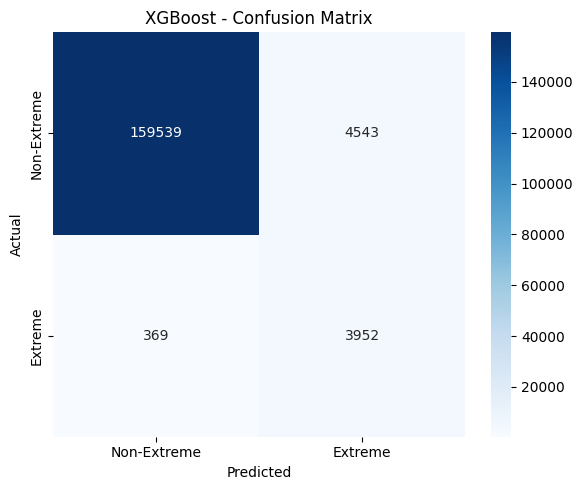

In [30]:
# ==========================================================
#  XGBOOST EVALUATION
# ==========================================================

# Calculate accuracy
xgb_accuracy = accuracy_score(
    y_test_class,
    y_pred_xgb
)

# Classification report
xgb_report = classification_report(
    y_test_class,
    y_pred_xgb,
    target_names=["Non-Extreme", "Extreme"],
    digits=4
)

# Confusion matrix
xgb_cm = confusion_matrix(
    y_test_class,
    y_pred_xgb
)

# Display results
print("XGBoost Performance")
print("=" * 50)

print(f"Accuracy : {xgb_accuracy:.4f}")

print("\nClassification Report:")
print(xgb_report)

print("Confusion Matrix:")
print(xgb_cm)

# Plot confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    xgb_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Extreme", "Extreme"],
    yticklabels=["Non-Extreme", "Extreme"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("XGBoost - Confusion Matrix")

plt.tight_layout()
plt.show()

#  CLASSIFICATION MODEL COMPARISON

In [31]:
# ==========================================================
#  CLASSIFICATION MODEL COMPARISON
# ==========================================================

# Generate classification reports as dictionaries
logistic_metrics = classification_report(
    y_test_class,
    y_pred_logistic,
    output_dict=True
)

nb_metrics = classification_report(
    y_test_class,
    y_pred_nb,
    output_dict=True
)

svm_metrics = classification_report(
    y_test_class,
    y_pred_svm,
    output_dict=True
)

rf_metrics = classification_report(
    y_test_class,
    y_pred_rf,
    output_dict=True
)

xgb_metrics = classification_report(
    y_test_class,
    y_pred_xgb,
    output_dict=True
)

# Create comparison table
classification_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "Linear SVM",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        logistic_metrics["accuracy"],
        nb_metrics["accuracy"],
        svm_metrics["accuracy"],
        rf_metrics["accuracy"],
        xgb_metrics["accuracy"]
    ],
    "Extreme Precision": [
        logistic_metrics["1"]["precision"],
        nb_metrics["1"]["precision"],
        svm_metrics["1"]["precision"],
        rf_metrics["1"]["precision"],
        xgb_metrics["1"]["precision"]
    ],
    "Extreme Recall": [
        logistic_metrics["1"]["recall"],
        nb_metrics["1"]["recall"],
        svm_metrics["1"]["recall"],
        rf_metrics["1"]["recall"],
        xgb_metrics["1"]["recall"]
    ],
    "Extreme F1": [
        logistic_metrics["1"]["f1-score"],
        nb_metrics["1"]["f1-score"],
        svm_metrics["1"]["f1-score"],
        rf_metrics["1"]["f1-score"],
        xgb_metrics["1"]["f1-score"]
    ]
})

# Round values
classification_comparison[
    ["Accuracy", "Extreme Precision", "Extreme Recall", "Extreme F1"]
] = classification_comparison[
    ["Accuracy", "Extreme Precision", "Extreme Recall", "Extreme F1"]
].round(4)

print("Classification Model Comparison")
print("=" * 80)

display(classification_comparison)

Classification Model Comparison


,Model,Accuracy,Extreme Precision,Extreme Recall,Extreme F1
0,Logistic Regression,0.9635,0.4091,0.9482,0.5716
1,Naive Bayes,0.7534,0.0935,0.9910,0.1710
2,Linear SVM,0.9616,0.3963,0.9502,0.5593
3,Random Forest,0.9808,0.9892,0.2543,0.4046
4,XGBoost,0.9708,0.4652,0.9146,0.6167


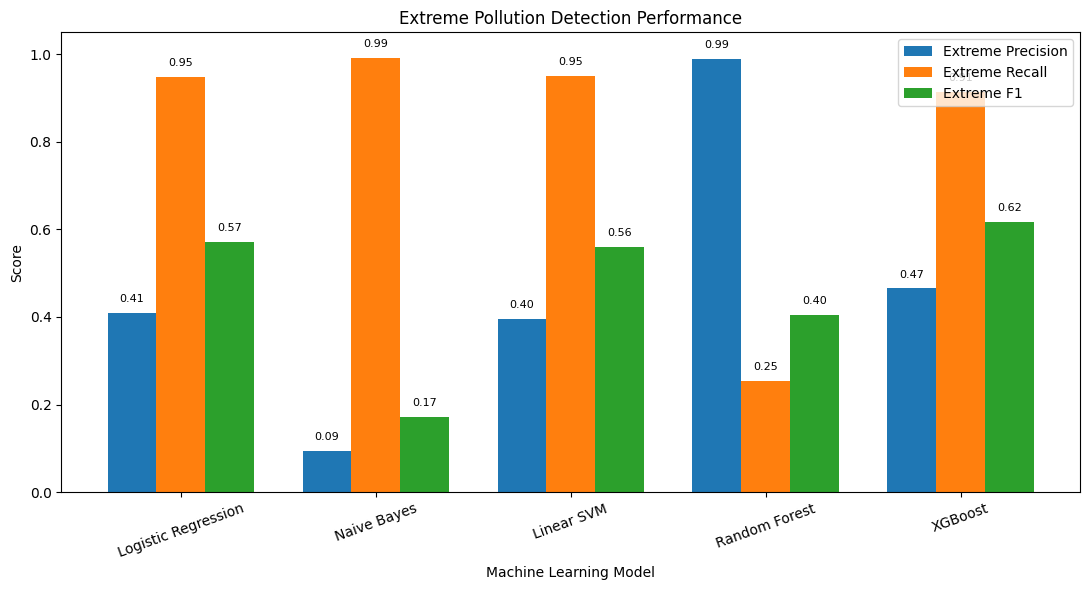

In [32]:
# ==========================================================
#  EXTREME POLLUTION MODEL COMPARISON
# ==========================================================

plt.figure(figsize=(11, 6))

models = classification_comparison["Model"]

x = np.arange(len(models))
width = 0.25

precision_values = classification_comparison["Extreme Precision"]
recall_values = classification_comparison["Extreme Recall"]
f1_values = classification_comparison["Extreme F1"]

bars1 = plt.bar(
    x - width,
    precision_values,
    width,
    label="Extreme Precision"
)

bars2 = plt.bar(
    x,
    recall_values,
    width,
    label="Extreme Recall"
)

bars3 = plt.bar(
    x + width,
    f1_values,
    width,
    label="Extreme F1"
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.title("Extreme Pollution Detection Performance")

plt.xticks(x, models, rotation=20)
plt.ylim(0, 1.05)

plt.legend()

# Add values above bars
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.02,
            f"{height:.2f}",
            ha="center",
            va="bottom",
            fontsize=8
        )

plt.tight_layout()
plt.show()

## Classification Analysis — Key Findings

The classification task was designed to identify extreme pollution events, defined as US_AQI ≥ 201.

The test dataset contained 168,403 observations, of which 4,321 (2.57%) were classified as extreme pollution events.

The five classification models showed different performance patterns under this imbalanced classification setting. Logistic Regression and Linear SVM detected most extreme events, with extreme recall values of 94.82% and 95.02%, respectively. Naive Bayes achieved an extreme recall of 99.10%, but its extreme precision was only 9.35%, indicating a high number of false positive predictions.

Random Forest produced high overall accuracy (98.08%) and high extreme precision (98.92%), but its extreme recall was only 25.43%, meaning that many actual extreme events were missed.

XGBoost achieved an extreme recall of 91.46%, extreme precision of 46.52%, and extreme F1-score of 61.67%.

These results demonstrate that overall classification accuracy alone does not adequately describe model reliability during extreme pollution events. The models exhibited different precision-recall trade-offs under severe pollution conditions.

Therefore, extreme-event-specific metrics such as precision, recall, and F1-score are necessary for evaluating model robustness in this study.

#  K-MEANS 

In [33]:
# ==========================================================
#  K-MEANS DATA PREPARATION
# ==========================================================

# Features selected for environmental clustering
kmeans_features = [
    "PM2_5_ugm3",
    "PM10_ugm3",
    "CO_ugm3",
    "NO2_ugm3",
    "SO2_ugm3",
    "O3_ugm3",
    "Dust_ugm3",
    "AOD",
    "Temp_2m_C",
    "Humidity_Percent",
    "Wind_Speed_10m_kmh",
    "Pressure_MSL_hPa",
    "Precipitation_mm"
]

# Use the cleaned original feature dataset
kmeans_data = X_clean[kmeans_features].copy()

print("K-Means feature preparation completed!")

print("\nSelected Features:")
print(kmeans_features)

print("\nOriginal K-Means Dataset Shape:")
print(kmeans_data.shape)

print("\nMissing Values:")
print(kmeans_data.isnull().sum().sum())

# Take a fixed random sample for clustering
kmeans_sample = kmeans_data.sample(
    n=50000,
    random_state=42
).copy()

print("\nK-Means Sample Shape:")
print(kmeans_sample.shape)

K-Means feature preparation completed!

Selected Features:
['PM2_5_ugm3', 'PM10_ugm3', 'CO_ugm3', 'NO2_ugm3', 'SO2_ugm3', 'O3_ugm3', 'Dust_ugm3', 'AOD', 'Temp_2m_C', 'Humidity_Percent', 'Wind_Speed_10m_kmh', 'Pressure_MSL_hPa', 'Precipitation_mm']

Original K-Means Dataset Shape:
(842015, 13)

Missing Values:
0

K-Means Sample Shape:
(50000, 13)


In [34]:
# ==========================================================
#  K-MEANS FEATURE SCALING
# ==========================================================

# Create scaler for K-Means
kmeans_scaler = StandardScaler()

# Scale the selected features
kmeans_scaled = kmeans_scaler.fit_transform(kmeans_sample)

print("K-Means feature scaling completed!")

print("\nScaled Data Shape:")
print(kmeans_scaled.shape)

print("\nMean of scaled features:",
      round(kmeans_scaled.mean(), 6))

print("Standard deviation of scaled features:",
      round(kmeans_scaled.std(), 6))

K-Means feature scaling completed!

Scaled Data Shape:
(50000, 13)

Mean of scaled features: 0.0
Standard deviation of scaled features: 1.0


Calculating Elbow Method...
K = 2 | Inertia = 539616.50
K = 3 | Inertia = 475318.99
K = 4 | Inertia = 425515.86
K = 5 | Inertia = 383409.51
K = 6 | Inertia = 352716.58
K = 7 | Inertia = 326079.39
K = 8 | Inertia = 310864.99


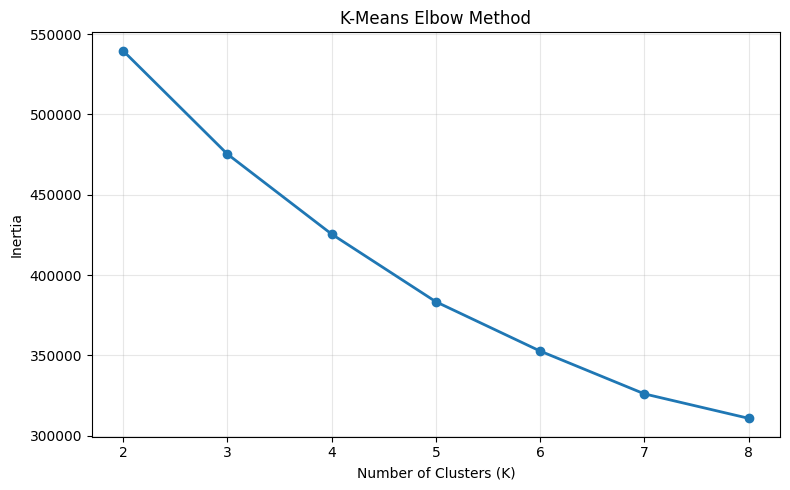

In [35]:
# ==========================================================
#  K-MEANS ELBOW METHOD
# ==========================================================

# Range of cluster values to test
k_values = range(2, 9)

inertias = []

print("Calculating Elbow Method...")

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(kmeans_scaled)
    inertias.append(kmeans.inertia_)
    
    print(f"K = {k} | Inertia = {kmeans.inertia_:.2f}")

# Plot Elbow Curve
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertias,
    marker="o",
    linewidth=2
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method")

plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [36]:
# ==========================================================
#  SILHOUETTE SCORE VALIDATION
# ==========================================================

from sklearn.metrics import silhouette_score

# Use a fixed subset for silhouette validation
silhouette_sample = kmeans_scaled[:10000]

silhouette_results = {}

print("Calculating Silhouette Scores...\n")

for k in [4, 5, 6]:
    
    kmeans_test = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    cluster_labels = kmeans_test.fit_predict(silhouette_sample)
    
    score = silhouette_score(
        silhouette_sample,
        cluster_labels
    )
    
    silhouette_results[k] = score
    
    print(f"K = {k} | Silhouette Score = {score:.4f}")

print("\nSilhouette validation completed!")

Calculating Silhouette Scores...

K = 4 | Silhouette Score = 0.1838
K = 5 | Silhouette Score = 0.1633
K = 6 | Silhouette Score = 0.1700

Silhouette validation completed!


In [37]:
# ==========================================================
#  FINAL K-MEANS CLUSTERING
# ==========================================================

# Final number of clusters
FINAL_K = 4

# Create final K-Means model
kmeans_model = KMeans(
    n_clusters=FINAL_K,
    random_state=42,
    n_init=10
)

# Fit model and generate cluster labels
kmeans_labels = kmeans_model.fit_predict(kmeans_scaled)

# Add cluster labels to the sampled data
kmeans_result = kmeans_sample.copy()
kmeans_result["Cluster"] = kmeans_labels

print("Final K-Means clustering completed!")

print("\nNumber of Clusters:", FINAL_K)

print("\nCluster Distribution:")
print(
    kmeans_result["Cluster"]
    .value_counts()
    .sort_index()
)

print("\nCluster Percentage:")
print(
    (
        kmeans_result["Cluster"]
        .value_counts(normalize=True)
        .sort_index() * 100
    ).round(2)
)

Final K-Means clustering completed!

Number of Clusters: 4

Cluster Distribution:
Cluster
0    17250
1      183
2    27105
3     5462
Name: count, dtype: int64

Cluster Percentage:
Cluster
0    34.50
1     0.37
2    54.21
3    10.92
Name: proportion, dtype: float64


In [38]:
# ==========================================================
#  K-MEANS CLUSTER PROFILE ANALYSIS
# ==========================================================

# Calculate mean values of selected features for each cluster
cluster_profile = (
    kmeans_result
    .groupby("Cluster")[kmeans_features]
    .mean()
    .round(2)
)

print("K-Means Cluster Profiles")
print("=" * 80)

display(cluster_profile)

K-Means Cluster Profiles


,PM2_5_ugm3,PM10_ugm3,CO_ugm3,NO2_ugm3,SO2_ugm3,O3_ugm3,Dust_ugm3,AOD,Temp_2m_C,Humidity_Percent,Wind_Speed_10m_kmh,Pressure_MSL_hPa,Precipitation_mm
Cluster,,,,,,,,,,,,,
0,32.42,55.85,337.65,9.41,13.13,118.21,30.70,0.52,28.95,54.09,10.94,1007.43,0.08
1,124.97,918.83,491.10,18.19,18.03,120.67,1588.43,0.83,30.07,42.99,10.42,1004.68,0.03
2,23.72,33.57,358.94,12.08,6.92,61.23,5.96,0.38,20.72,81.98,6.61,1010.20,0.29
3,94.63,136.77,1282.93,57.89,49.71,55.02,24.57,0.69,20.51,74.02,6.52,1013.10,0.03


In [39]:
# ==========================================================
#  AQI PROFILE BY CLUSTER
# ==========================================================

# Add actual US_AQI to the K-Means sample
kmeans_result["US_AQI"] = y_clean.loc[kmeans_result.index]

# Calculate AQI statistics for each cluster
cluster_aqi_profile = (
    kmeans_result
    .groupby("Cluster")["US_AQI"]
    .agg(
        Mean_AQI="mean",
        Median_AQI="median",
        Min_AQI="min",
        Max_AQI="max",
        Extreme_Count=lambda x: (x >= 201).sum()
    )
    .round(2)
)

# Calculate percentage of extreme observations in each cluster
cluster_aqi_profile["Extreme_Percentage"] = (
    kmeans_result
    .groupby("Cluster")["US_AQI"]
    .apply(lambda x: (x >= 201).mean() * 100)
    .round(2)
)

print("AQI Profile by K-Means Cluster")
print("=" * 80)

display(cluster_aqi_profile)

AQI Profile by K-Means Cluster


,Mean_AQI,Median_AQI,Min_AQI,Max_AQI,Extreme_Count,Extreme_Percentage
Cluster,,,,,,
0,104.06,97.0,13.0,864.0,223,1.29
1,676.78,574.0,70.0,2740.0,157,85.79
2,74.44,67.0,9.0,403.0,8,0.03
3,163.12,162.0,51.0,1808.0,446,8.17


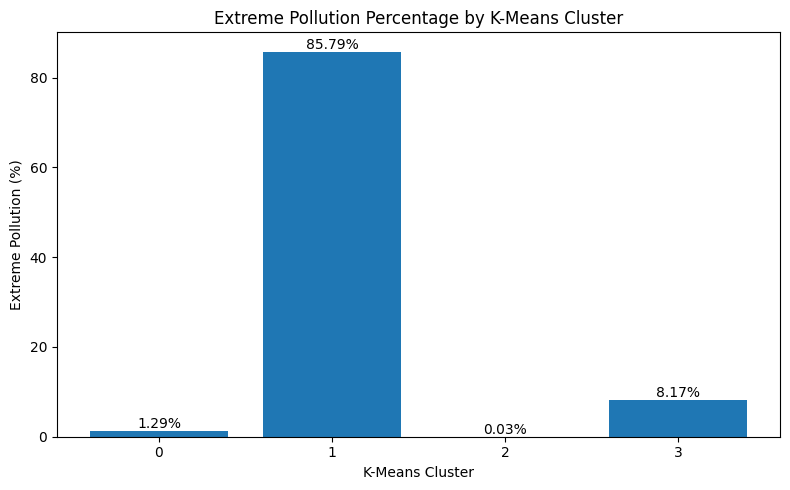

In [40]:
# ==========================================================
#  EXTREME POLLUTION BY K-MEANS CLUSTER
# ==========================================================

plt.figure(figsize=(8, 5))

clusters = cluster_aqi_profile.index
extreme_percentages = cluster_aqi_profile["Extreme_Percentage"]

bars = plt.bar(
    clusters.astype(str),
    extreme_percentages
)

plt.xlabel("K-Means Cluster")
plt.ylabel("Extreme Pollution (%)")
plt.title("Extreme Pollution Percentage by K-Means Cluster")

# Add percentage values
for bar, value in zip(bars, extreme_percentages):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

## K-Means Clustering — Key Findings

K-Means clustering was performed using 50,000 randomly sampled observations and 13 environmental and pollutant-related features.

The Elbow Method was evaluated for K values from 2 to 8. Since the elbow curve did not show a sharp single elbow, Silhouette Score validation was additionally performed for K = 4, 5, and 6. K = 4 produced the highest Silhouette Score among the tested values (0.1838), and was therefore selected for the final clustering analysis.

The four clusters showed distinct environmental profiles. Cluster 1 was a rare cluster containing only 0.37% of the sampled observations, but 85.79% of its observations had US_AQI ≥ 201. This cluster also showed substantially higher PM10, Dust, and AOD concentrations.

Cluster 3 showed relatively high concentrations of CO, NO2, and SO2 and had an extreme-pollution proportion of 8.17%. Cluster 2 represented the lowest-pollution profile, with only 0.03% of its observations classified as extreme.

These results indicate that distinct environmental conditions identified through unsupervised clustering are strongly associated with different levels of AQI severity. The clustering analysis therefore provides an additional perspective on the environmental patterns associated with extreme pollution events.

# FINAL MACHINE LEARNING CONCLUSION

## Research Question

**Do machine-learning models remain reliable during extreme pollution episodes, or does their prediction performance degrade when AQI becomes severe?**

---

## 1. Regression Analysis

Linear Regression was used to predict continuous US_AQI values.

The model achieved:

- Overall MAE: **23.34**
- Overall RMSE: **56.59**
- Overall R²: **0.7460**

However, when evaluated specifically on extreme pollution observations (US_AQI ≥ 201):

- Extreme MAE: **201.97**
- Extreme RMSE: **313.50**
- Extreme R²: **0.4916**

The substantial increase in prediction error and decrease in R² indicate that the regression model's predictive performance changed considerably under extreme pollution conditions.

---

## 2. Extreme Pollution Classification

Five classification models were evaluated for identifying extreme pollution events.

| Model | Accuracy | Extreme Precision | Extreme Recall | Extreme F1 |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.9635 | 0.4091 | 0.9482 | 0.5716 |
| Naive Bayes | 0.7534 | 0.0935 | 0.9910 | 0.1710 |
| Linear SVM | 0.9616 | 0.3963 | 0.9502 | 0.5593 |
| Random Forest | 0.9808 | 0.9892 | 0.2543 | 0.4046 |
| XGBoost | 0.9708 | 0.4652 | 0.9146 | 0.6167 |

The results demonstrate substantial differences between overall accuracy and extreme-event detection performance.

For example, Random Forest achieved 98.08% overall accuracy but detected only 25.43% of the actual extreme events. In contrast, Naive Bayes detected 99.10% of extreme events but produced a large number of false positive predictions, resulting in an extreme precision of only 9.35%.

This demonstrates that accuracy alone is insufficient for evaluating model reliability during rare extreme pollution events.

---

## 3. Unsupervised K-Means Analysis

K-Means clustering was performed using 50,000 sampled observations and 13 environmental and pollutant-related variables.

Four clusters were selected after combining Elbow Method analysis with Silhouette Score validation.

The clusters showed distinct environmental profiles.

A particularly notable cluster was Cluster 1, which represented only **0.37%** of the sampled observations but had an extreme-pollution proportion of **85.79%**.

Cluster 1 also showed substantially higher PM10, Dust, and AOD concentrations.

Cluster 3 showed relatively high concentrations of CO, NO2, and SO2 and had an extreme-pollution proportion of **8.17%**.

These findings indicate that distinct environmental conditions are strongly associated with different AQI severity patterns.

---

## 4. Overall Research Finding

The machine-learning experiments provide evidence that model performance is not uniform across pollution conditions.

Linear Regression showed substantially higher prediction errors when evaluated on extreme pollution observations compared with the overall test set.

The classification experiments also showed that models can behave very differently when detecting rare extreme events. Some models produced high extreme-event recall but many false positives, while others produced high precision but missed a substantial proportion of actual extreme events.

Therefore, evaluating machine-learning models only using overall performance metrics can hide important weaknesses under extreme pollution conditions.

The results support the need for **extreme-condition-specific evaluation** when assessing the robustness and reliability of air-quality machine-learning models.

---

## 5. Research Implication

For air-quality prediction systems, model evaluation should not rely exclusively on overall accuracy or average prediction error.

Performance should also be examined separately under severe and extreme pollution conditions using metrics such as:

- MAE
- RMSE
- R²
- Precision
- Recall
- F1-score
- Confusion Matrix

This provides a more complete assessment of whether machine-learning models remain reliable when pollution conditions become unusually severe.